In [1]:
# %load_ext autoreload
# %autoreload 2
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent.parent.parent.parent.parent.parent
sys.path.insert(0, str(PROJECT_ROOT))
print(PROJECT_ROOT)

from src.inference import generate, encode_cells, get_latent_mean, get_mean, load_data, load_model, sample_around_point, calc_r2_pearson
import scanpy as sc
import os
import anndata
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.pyplot import rc_context
import anndata
import seaborn as sns
import torch
import torch
import torch.distributed as dist
from torch.nn.parallel import DistributedDataParallel as DDP
import scipy.sparse as sp
print("CUDA Available: ", torch.cuda.is_available())
print("Number of GPUs: ", torch.cuda.device_count())


/lustre/work/yaolab/mzhou10/squidiff_practice/Squidiff/project_v3
CUDA Available:  True
Number of GPUs:  1


In [2]:
for i in [200,500,2000,5000,10000,20000,30000]:
    predict_data_origin = sc.read_h5ad(f"../experiments/squidiff_exp0_interception_predict_day_12_top{i}.h5ad")
    indices = np.random.choice(
        predict_data_origin.n_obs,
        size=8229,
        replace=False
    )

    predict_data_8229 = predict_data_origin[indices, :].copy()

    print(f"Subset {i}: {predict_data_8229.shape}")
    predict_data_8229.write_h5ad(f"squidiff_exp0_interception_predict_day_12_top{i}_8229.h5ad")

Subset 200: (8229, 200)
Subset 500: (8229, 500)
Subset 2000: (8229, 2000)
Subset 5000: (8229, 5000)
Subset 10000: (8229, 10000)
Subset 20000: (8229, 20000)
Subset 30000: (8229, 30000)


i 200
real_data: AnnData object with n_obs × n_vars = 8229 × 200
    obs: 'n_genes', 'n_counts', 'Cluster', 'leiden_R', 'Cell type', 'Sample_time', 'Group'
    var: 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'highly_variable_nbatches', 'mean', 'std', 'SNF', 'means_ForPickMock', 'dispersions', 'dispersions_norm'
    uns: 'Cell type_colors', 'hvg'
    obsm: 'X_scvi', 'X_umap'
    layers: 'empty', 'normalize_log', 'raw'
    obsp: 'connectivities', 'distances'
predict_data: AnnData object with n_obs × n_vars = 8229 × 200
r2,pearsonr: -1.5080360858492705 0.2182368670563116
383.7689 1.958039052577105
383.7689 1.958039052577105
max 383.7689
i 500
real_data: AnnData object with n_obs × n_vars = 8229 × 500
    obs: 'n_genes', 'n_counts', 'Cluster', 'leiden_R', 'Cell type', 'Sample_time', 'Group'
    var: 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'highly_variable_nbatches', 'mean', 'std', 'SNF'

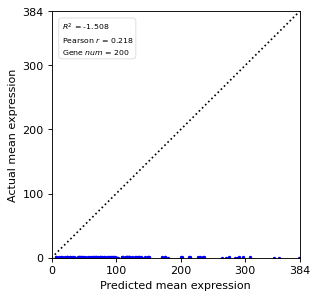

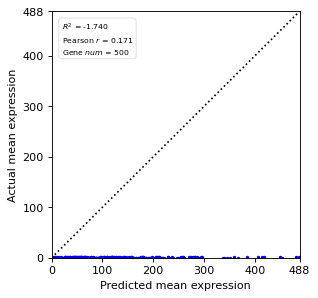

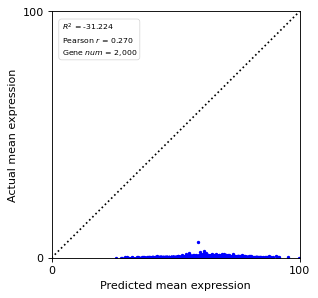

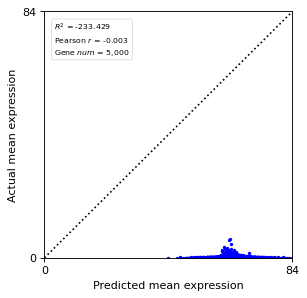

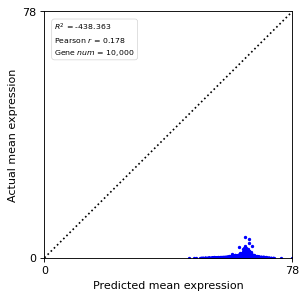

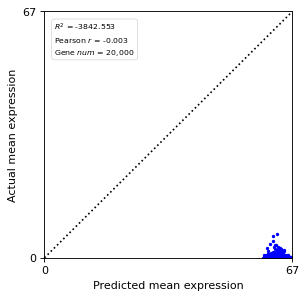

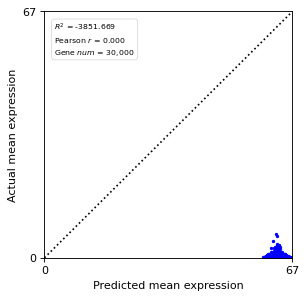

In [3]:
for i in [200,500,2000,5000,10000,20000,30000]:
  print("i",i)
  real_data = sc.read_h5ad(f"../../input/plant_real_test_day12_data_gene_top{i}.h5ad")
  # real_data = sc.read_h5ad("../../input/plant_test_day0_data.h5ad")
  print("real_data:",real_data)
  # print(data_2)

  predict_data = sc.read_h5ad(f"squidiff_exp0_interception_predict_day_12_top{i}_8229.h5ad")
  print("predict_data:",predict_data)
  r_all = []
  pearsonr_all = []
  r2, pearsonr,predict,real = calc_r2_pearson(predict_data,real_data)
  print("r2,pearsonr:",r2, pearsonr)

  # r2_new, pearson_new = calc_r2_pearson(predict_data, real_data)
  # print(r2_new, pearson_new)
  # r_all.append(['new method', "whole", 'predict day21 from test data day12', 'predict number:', predict_data.shape[0], 'test_data_number:',real_data.shape[0], 'r2_score:',r2])
  # pearsonr_all.append(['new method', "whole", 'predict day21 from test data day12', 'predict number:', predict_data.shape[0], 'test_data_number:',real_data.shape[0], 'pearson_score:',pearsonr])

  # pd.DataFrame(r_all).to_csv(os.path.join("new_method_r_all_new.csv"))
  # pd.DataFrame(pearsonr_all).to_csv(os.path.join("new_method_pearsonr_all_new.csv"))
  print(max(predict),max(real))
  fig, ax = plt.subplots(1,1,figsize=(4,4),dpi=80)
  plt.scatter(predict,
              real,
              s=4,
              c='blue'
            )
  limit = np.ceil(max(np.max(predict), np.max(real)))
  print(np.max(predict),np.max(real))
  plt.plot([0, limit], [0, limit], color="black", linestyle=":")
  plt.xlim([0, limit])
  plt.ylim([0, limit])
  if limit <= 8:
    ticks = np.arange(0, limit + 1, 1)
  else:    
    ticks = np.arange(0, limit + 1, 100)
      
  ticks = np.append(ticks, limit)
  ticks = np.unique(ticks)
  plt.xticks(ticks)
  plt.yticks(ticks)
  print("max",max(np.max(predict), np.max(real)))
  plt.xlabel(f"Predicted mean expression")
  plt.ylabel(f"Actual mean expression")
  ax.text(0.04, 0.96, f"$R^2$ = {r2:.3f}\nPearson $r$ = {pearsonr:.3f}\nGene $num$ = {len(predict):,}",
        transform=ax.transAxes, va="top", ha="left", fontsize=7, linespacing=1.4,
        bbox=dict(boxstyle="round,pad=0.35", fc="white", ec="0.8", lw=0.6, alpha=0.9))
  fig.savefig(os.path.join(f"pred_day_12_exp0_gene_number_{i}.pdf"), bbox_inches="tight")
  